# Imports

In [ ]:
# StateGraph builds and runs the workflow; START and END mark its boundaries.
from langgraph.graph import StateGraph, START, END

# ChatOpenAI is the LLM used by both prompt-chaining nodes.
from langchain_openai import ChatOpenAI

# TypedDict documents the keys and value types passed between nodes.
from typing import TypedDict

# Loads API credentials such as OPENAI_API_KEY from a local .env file.
from dotenv import load_dotenv


# Loading env variables

In [ ]:
# Load environment variables so ChatOpenAI can find the configured API key.
load_dotenv()


True

# Define LLM

In [ ]:
# Create one model instance and reuse it in both workflow nodes.
# ChatOpenAI reads its API key from the environment loaded above.
model = ChatOpenAI()


# Define State

In [ ]:
# Define the shared data shape that flows from one graph node to the next.
class BlogState(TypedDict):
    title: str     # Topic supplied when the workflow starts.
    outline: str   # Outline generated by the first node.
    content: str   # Full blog generated by the second node.


# Creating Nodes

In [ ]:
def create_outline(state: BlogState) -> BlogState:
    """Generate a detailed outline from the title and add it to the state."""
    # Read the topic provided in the initial graph state.
    title = state['title']

    # Ask the LLM for an outline; .content extracts plain text from its response.
    prompt = f'Generate a detailed outline for a blog on the topic - {title}'
    outline = model.invoke(prompt).content

    # Save the outline so the next node can use it to write the blog.
    state['outline'] = outline
    return state


In [ ]:
def create_blog(state: BlogState) -> BlogState:
    """Write the full blog using the title and outline from the prior node."""
    title = state['title']
    outline = state['outline']

    # Pass the first node's outline into the second LLM prompt.
    prompt = f'Write a detailed blog on the title - {title} using the follwing outline \n {outline}'
    content = model.invoke(prompt).content

    # Store the finished blog in the shared state returned by the workflow.
    state['content'] = content
    return state


# Define and Compile Graph

In [ ]:
# Create a graph whose nodes all read and update BlogState.
graph = StateGraph(BlogState)

# Register each function as a node; registration does not run it yet.
graph.add_node('create_outline', create_outline)
graph.add_node('create_blog', create_blog)

# Set the fixed sequence: input -> outline -> blog -> output.
graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', END)

# Compile the graph into an executable workflow.
workflow = graph.compile()


# Execute the Graph

In [ ]:
# Provide the first node with the topic; later nodes add outline and content.
intial_state = {'title': 'Rise of AI in India in 2026'}

# Run the nodes in graph order and receive the final state with all fields.
final_state = workflow.invoke(intial_state)

# Inspect the complete state returned by the workflow.
print(final_state)


{'title': 'Rise of AI in India in 2026', 'outline': "I. Introduction\n    A. Brief overview of Artificial Intelligence (AI)\n    B. Current status of AI in India\n    C. Significance of AI in various industries\n\nII. History of AI in India\n    A. Evolution of AI technology in India\n    B. Major milestones and developments in the field of AI\n    C. Adoption of AI in different sectors\n\nIII. Rise of AI in India in 2026\n    A. Current state of AI in India in 2026\n    B. Growth and expansion of AI technology in various industries\n    C. Impact of AI on Indian economy and society\n\nIV. Key players in the AI industry in India\n    A. Overview of leading AI companies in India\n    B. Contribution of startups and research institutions to the AI ecosystem\n    C. Collaboration between government and private sector for AI development\n\nV. Challenges and opportunities in AI adoption in India\n    A. Regulatory and ethical issues surrounding AI technology\n    B. Skilling and reskilling 

In [ ]:
# View the intermediate outline created by the first node.
print(final_state['outline'])


I. Introduction
    A. Brief overview of Artificial Intelligence (AI)
    B. Current status of AI in India
    C. Significance of AI in various industries

II. History of AI in India
    A. Evolution of AI technology in India
    B. Major milestones and developments in the field of AI
    C. Adoption of AI in different sectors

III. Rise of AI in India in 2026
    A. Current state of AI in India in 2026
    B. Growth and expansion of AI technology in various industries
    C. Impact of AI on Indian economy and society

IV. Key players in the AI industry in India
    A. Overview of leading AI companies in India
    B. Contribution of startups and research institutions to the AI ecosystem
    C. Collaboration between government and private sector for AI development

V. Challenges and opportunities in AI adoption in India
    A. Regulatory and ethical issues surrounding AI technology
    B. Skilling and reskilling challenges in the workforce
    C. Opportunities for innovation and growth 

In [ ]:
# View the full blog produced by the second node from that outline.
print(final_state['content'])




I. Introduction

A. Artificial Intelligence (AI) is a branch of computer science that aims to create intelligent machines that can mimic human cognitive functions such as learning, problem-solving, and decision-making.

B. In recent years, AI has gained significant traction in India with various industries like healthcare, finance, manufacturing, and agriculture leveraging AI technologies to improve efficiency and productivity.

C. The significance of AI in various industries lies in its ability to automate repetitive tasks, analyze large amounts of data quickly, and make predictions and recommendations based on patterns identified in the data.

II. History of AI in India

A. The evolution of AI technology in India dates back to the early 2000s with the establishment of research institutions and AI labs in universities and companies.

B. Major milestones in the field of AI in India include the introduction of AI-driven chatbots, recommendation engines, and voice recognition systems i

# Visualize Graph (Optional)

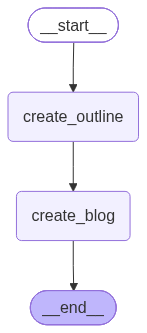

In [ ]:
# Render the compiled workflow's Mermaid diagram as an image.
from IPython.display import Image

Image(workflow.get_graph().draw_mermaid_png())
